# 05 · Forecast-Horizon Experiments

**Objective.** How forecast error grows with lead time (24/48/72/96/168 h, input window
fixed at 24 h), and how the SWC-only CNN compares to the persistence baseline at each
horizon.

**Provenance & reproducibility**

- **Results shown here:** ⬇ **loaded from Nov-17** (`results/nov17_results.csv`); the pivot is computed here.
- **Experimental setup:** SWC-only CNN (config A) vs persistence, averaged over the 5 held-out station-years, horizons 24–168 h, 24 h window.
- **Implementation:** `src.evaluation.run_fold(..., feature_cols=C.feature_columns('swc'), horizon=h)`; persistence = predict the window's last `SWC_20` value (`src.evaluation.persistence_rmse`).
- **Original code:** the 150 production CNN runs and the HP sweep were generated by the original monolithic notebook, preserved at `archive/cnn_experiments_original_monolithic.ipynb` (run live on Google Colab GPU, 2026-11-17); the notebooks here are the refactored, `src/`-based version of that same pipeline.
- **Reproduce:** shell loop over horizons (one per call): `for H in 24 48 72 96 168; do python main.py --features swc --horizon $H; done`.

In [1]:
# --- project setup: portable across local / Google Drive / fresh Colab ---
import os, sys

def find_project_root(marker="src"):
    # 1) walk up from the current directory (local checkout or Drive upload)
    p = os.path.abspath(os.getcwd())
    while p != os.path.dirname(p):
        if os.path.isdir(os.path.join(p, marker)):
            return p
        p = os.path.dirname(p)
    # 2) common Colab upload locations
    for c in ("/content/soil_moisture_research",
              "/content/drive/MyDrive/soil_moisture_research"):
        if os.path.isdir(os.path.join(c, marker)):
            return c
    raise FileNotFoundError(
        "Could not find the project root (a folder containing 'src/').\n"
        "Upload the whole soil_moisture_research/ folder to Drive/Colab and "
        "open this notebook from inside notebooks/.")

ROOT = find_project_root()
sys.path.insert(0, ROOT)
os.chdir(ROOT)
print("project root set ->", os.path.basename(ROOT))  # portable: no absolute path

project root set -> soil_moisture_research


In [2]:
import pandas as pd
res = pd.read_csv('results/nov17_results.csv')
tab = res[res.config.isin(['A: SWC_20 only','persistence'])]\
        .pivot_table(index='horizon', columns='config', values='RMSE', aggfunc='mean')
# Improvement = mean over the 5 station-years of each fold's % gain vs persistence
# (equal weight per station-year; matches the report's Table 3 method).
cnn = res[res.config=='A: SWC_20 only']
tab['CNN_vs_persist_%'] = cnn.groupby('horizon')['impr_vs_persist_%'].mean()
tab.round(4)

config,A: SWC_20 only,persistence,CNN_vs_persist_%
horizon,,,
24,0.0137,0.0139,1.2745
48,0.0190,0.0192,0.8260
72,0.0229,0.0230,0.2692
96,0.0263,0.0265,0.2525
168,0.0349,0.0349,-0.4620


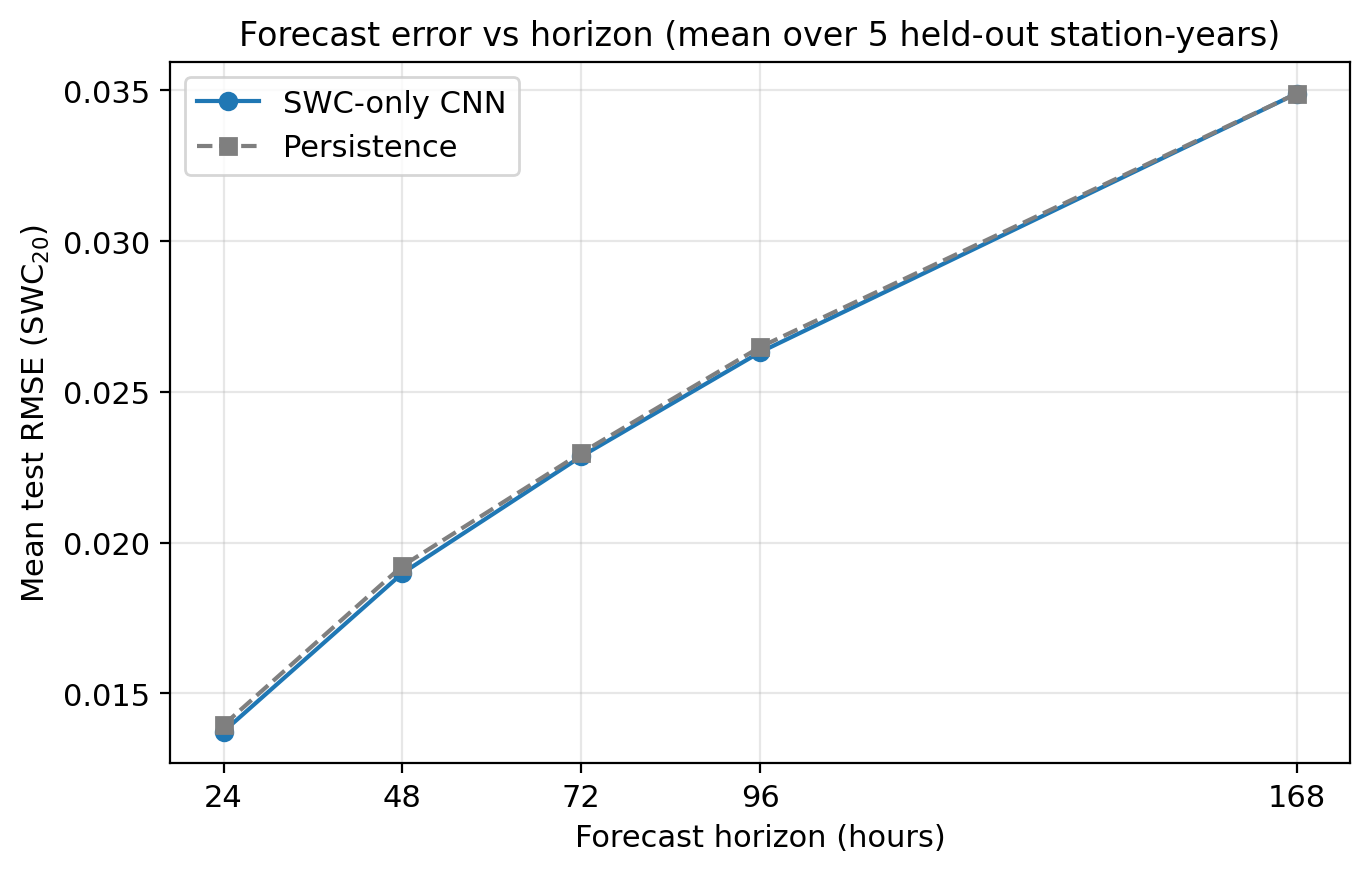

In [3]:
from IPython.display import Image, display
display(Image('figures/fig_rmse_vs_horizon.png'))

**Takeaway.** RMSE rises monotonically with horizon. The SWC-only CNN's edge over
persistence is small and shrinks from +1.3% at 24 h to −0.5% at 168 h — persistence is a
strong baseline for slowly-varying soil moisture, which is the backdrop against which the
(small) exogenous-feature effects in notebook 07 must be judged.